# Phase 2 — Dataset Validation (IndoPref)

## 1. Objective / Context
**WHY:** Mengukur reliabilitas *LLM-as-a-Judge* membutuhkan dataset preferensi yang bebas dari anomali. Notebook ini memuat dataset IndoPref, memvalidasi skema, dan melakukan *stratified sampling* secara deterministik untuk menjamin keabsahan metrik evaluasi di tahap akhir.

## 2. Setup & Google Drive Mount
**WHY:** Menyimpan hasil dataset (*cache*) ke dalam Google Drive agar eksekusi eksperimen (Pilot & Main) konsisten antar-sesi *runtime* Google Colab.

In [1]:
import os
import json
from typing import Tuple

import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from huggingface_hub import login

# Global Configuration
RANDOM_SEED: int = 42
PROJECT_ROOT: str = '/content/drive/MyDrive/LLMReliability'
DATA_RAW_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'raw')
DATA_PROCESSED_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'processed')
MODELS_DIR: str = os.path.join(PROJECT_ROOT, 'models')
RESULTS_DIR: str = os.path.join(PROJECT_ROOT, 'results')

DATASET_NAME: str = "davidanugraha/IndoPref"
SPLIT_NAME: str = "test"
EXPECTED_ROWS: int = 4099

# Mount Drive & Create Architecture
try:
    from google.colab import drive
    drive.mount('/content/drive')
    
    # Authenticate to HuggingFace securely
    secrets_path = '/content/drive/MyDrive/secrets.json'
    if os.path.exists(secrets_path):
        with open(secrets_path, 'r') as f:
            secrets = json.load(f)
        hf_token = secrets.get("HF_TOKEN")
        if hf_token:
            login(token=hf_token)
            print("[INFO] Successfully authenticated to HuggingFace Hub.")
except ImportError:
    print("[INFO] Not in Colab environment. Using local storage.")
    
# Initialize Directory Structure
for d in [DATA_RAW_DIR, DATA_PROCESSED_DIR, MODELS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)
print("[INFO] Project directory structure verified.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[INFO] Successfully authenticated to HuggingFace Hub.
[INFO] Project directory structure verified.


## 3. Dependencies & Data Loading
**WHY:** Memastikan struktur dataset di hulu (HuggingFace) tidak berubah secara diam-diam dengan memverifikasi total baris data yang dimuat.

In [2]:
print(f"Loading {DATASET_NAME} ({SPLIT_NAME})...")
dataset = load_dataset(DATASET_NAME, split=SPLIT_NAME)
df_indopref: pd.DataFrame = dataset.to_pandas()

# [NEW] Bronze Layer Checkpoint: Backing up Raw Data
raw_path = os.path.join(DATA_RAW_DIR, 'indopref_raw.parquet')
df_indopref.to_parquet(raw_path, index=False)
print(f"[INFO] Raw dataset backed up to Bronze Layer: {raw_path}")

assert len(df_indopref) == EXPECTED_ROWS, f"Dataset integrity error: Expected {EXPECTED_ROWS} rows, got {len(df_indopref)}"
df_indopref.info()

Loading davidanugraha/IndoPref (test)...
<class 'pandas.DataFrame'>
RangeIndex: 4099 entries, 0 to 4098
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   id              4099 non-null   int64
 1   original_id     4099 non-null   int64
 2   domain          4099 non-null   str  
 3   input           4099 non-null   str  
 4   response_1      4099 non-null   str  
 5   response_2      4099 non-null   str  
 6   chosen_model    4099 non-null   str  
 7   rejected_model  4099 non-null   str  
 8   actual_score    4099 non-null   str  
 9   language        4099 non-null   str  
dtypes: int64(2), str(8)
memory usage: 10.8 MB


## 4. Data Integrity Check
**WHY:** Menghindari kegagalan komputasi mahal (*OOM* atau *parsing error*) pada saat inferensi Qwen3 dengan memastikan tidak ada nilai `Null` atau kolom esensial yang hilang.

### 4.1 Schema Validation
Memastikan seluruh kolom wajib (seperti `input`, `response_1`, dll) tersedia di dataset.

In [3]:
required_cols = ['original_id', 'domain', 'input', 'response_1', 'response_2', 'actual_score']
missing = [c for c in required_cols if c not in df_indopref.columns]
assert not missing, f"Schema error: Missing columns {missing}"

### 4.2 Null & Empty String Check
Mendeteksi anomali teks kosong yang bisa menyebabkan model *Judge* berhalusinasi.

In [4]:
assert df_indopref.isnull().sum().sum() == 0, "Null values detected."
assert not df_indopref['response_1'].str.strip().eq("").any(), "Empty 'response_1' detected."
assert not df_indopref['response_2'].str.strip().eq("").any(), "Empty 'response_2' detected."

### 4.3 Duplicate Detection (Basic)
Menghitung jumlah duplikasi murni pada dataset.

In [5]:
# [NEW] Explicit Deduplication
duplicates_before = df_indopref.duplicated(subset=['original_id']).sum()
print(f"[INFO] Ditemukan {duplicates_before} duplikat original_id.")

if duplicates_before > 0:
    df_indopref = df_indopref.drop_duplicates(subset=['original_id']).copy()
    print(f"[INFO] Duplikat berhasil dihapus. Baris tersisa: {len(df_indopref)}")
else:
    print("[INFO] Tidak ada duplikat. Dataset bersih.")

# Re-verifikasi panjang dataset baru untuk mencegah pipeline error
EXPECTED_CLEAN_ROWS = len(df_indopref)
assert len(df_indopref) == EXPECTED_CLEAN_ROWS

[INFO] Ditemukan 3580 duplikat original_id.
[INFO] Duplikat berhasil dihapus. Baris tersisa: 519


## 5. Exploratory Data Analysis (EDA)
**WHY:** Memahami struktur data pra-sampling untuk menghindari data leakage dan kebuntuan inferensi (*OOM*) akibat teks yang terlalu panjang.

### 5.1 Data Inspection
Memeriksa secara visual struktur teks bahasa Indonesia pada sampel.

In [6]:
display(df_indopref[['domain', 'input', 'chosen_model', 'rejected_model']].head(3))

,domain,input,chosen_model,rejected_model
0,logic,Jika Anda menambah kecepatan kendaraan tiba-ti...,Aya-Expanse-8B,Llama-3.1-8B-Instruct
1,brainstorming,Jika Anda memiliki kesempatan untuk memulai ke...,GPT 4o,GPT 4o mini
2,logic,"Sebuah taman memiliki tiga jenis bunga: mawar,...",Gemini-1.5-Flash,Aya-Expanse-8B


### 5.2 Analisis Duplikasi Prompt (Preference Pairs)
Mengingat tingginya angka duplikasi (3580 dari 4099), kita memvisualisasikan berapa kali satu prompt unik dievaluasi.

Total Unique Prompts: 519


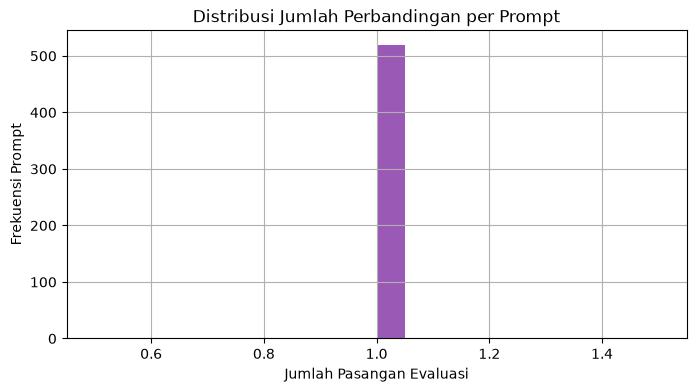

In [7]:
unique_prompts = df_indopref['original_id'].nunique()
print(f"Total Unique Prompts: {unique_prompts}")

# Visualisasi jumlah perbandingan per prompt
pair_counts = df_indopref.groupby('original_id').size()
fig, ax = plt.subplots(figsize=(8, 4))
pair_counts.hist(bins=20, ax=ax, color='#9b59b6')
ax.set_title('Distribusi Jumlah Perbandingan per Prompt')
ax.set_xlabel('Jumlah Pasangan Evaluasi')
ax.set_ylabel('Frekuensi Prompt')
plt.show()

### 5.3 Analisis Panjang Teks (Mitigasi OOM)
Menghitung estimasi panjang kata menggunakan **dataframe bayangan (df_eda)** untuk mencegah rusaknya/bocornya skema ekspor dataset asli.

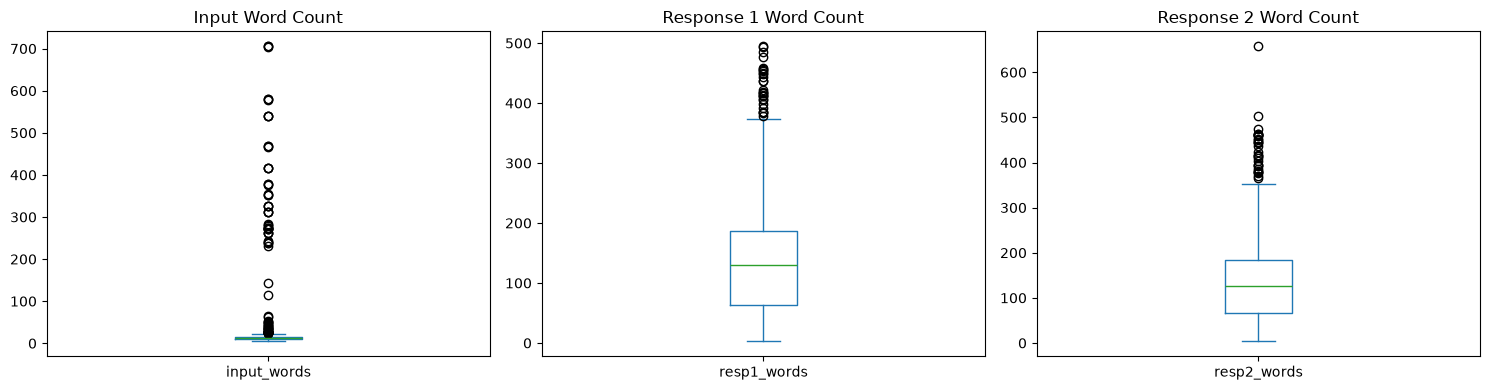

Max word count in a single text: 706 words.


In [8]:
df_eda = df_indopref.copy()
df_eda['input_words'] = df_eda['input'].apply(lambda x: len(str(x).split()))
df_eda['resp1_words'] = df_eda['response_1'].apply(lambda x: len(str(x).split()))
df_eda['resp2_words'] = df_eda['response_2'].apply(lambda x: len(str(x).split()))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df_eda['input_words'].plot(kind='box', ax=axes[0], title='Input Word Count')
df_eda['resp1_words'].plot(kind='box', ax=axes[1], title='Response 1 Word Count')
df_eda['resp2_words'].plot(kind='box', ax=axes[2], title='Response 2 Word Count')
plt.tight_layout()
plt.show()

max_words = df_eda[['input_words', 'resp1_words', 'resp2_words']].max().max()
print(f"Max word count in a single text: {max_words} words.")

### 5.4 Distribusi Model (Chosen vs Rejected)
Memahami model mana yang paling sering menang/kalah dalam anotasi manusia.

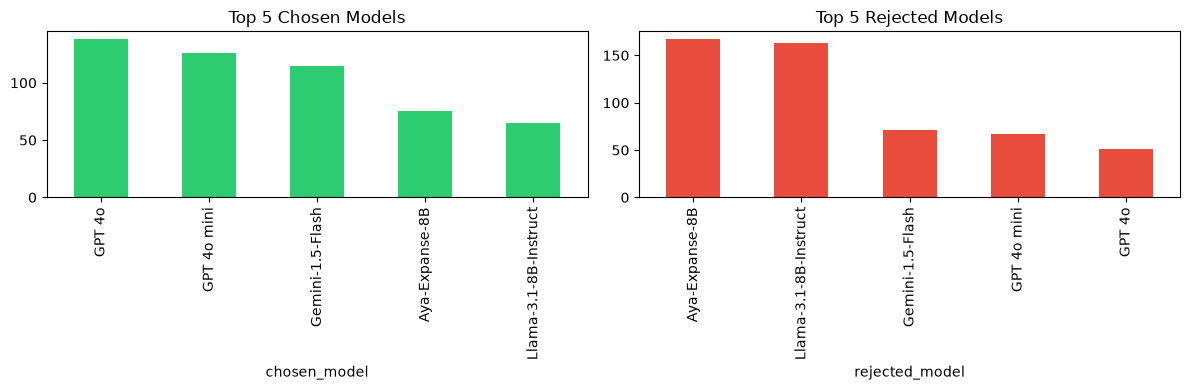

In [9]:
chosen_dist = df_indopref['chosen_model'].value_counts().head(5)
rejected_dist = df_indopref['rejected_model'].value_counts().head(5)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
chosen_dist.plot(kind='bar', ax=axes[0], title='Top 5 Chosen Models', color='#2ecc71')
rejected_dist.plot(kind='bar', ax=axes[1], title='Top 5 Rejected Models', color='#e74c3c')
plt.tight_layout()
plt.show()

## 6. Domain Distribution & Stratified Sampling
**WHY:** IndoPref terdiri dari 10 domain (seperti Logika, Komputer). *Stratified sampling* wajib digunakan agar 150 sampel *Pilot* dan 1000 sampel *Main* mewakili komposisi populasi aslinya secara proporsional.

[INFO] df_pilot di-set ke: 150 sampel.
[INFO] df_main di-set ke: 369 sampel.


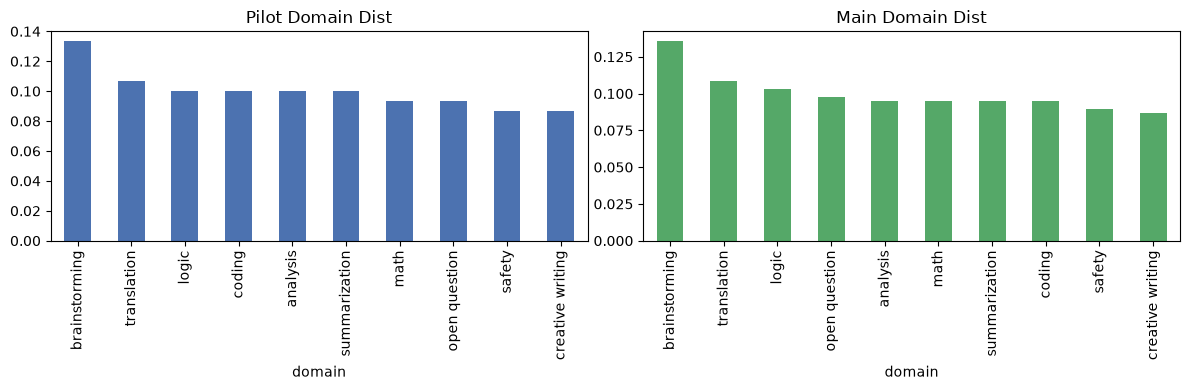

In [10]:
df_pilot: pd.DataFrame
df_remainder: pd.DataFrame
df_main: pd.DataFrame

# Pilot Split (150 samples)
df_pilot, df_remainder = train_test_split(
    df_indopref, train_size=150, stratify=df_indopref['domain'], random_state=RANDOM_SEED
)

# Main Split (All remaining samples)
# Fakta Mengejutkan: Setelah duplikat dihapus, dataset yang asalnya 4099 baris ternyata HANYA memiliki 519 prompt unik!
# Oleh karena itu, kita tidak bisa mengambil 1000 sampel. df_main akan menggunakan seluruh sisa data (369 sampel).
df_main = df_remainder.copy()
print(f"[INFO] df_pilot di-set ke: {len(df_pilot)} sampel.")
print(f"[INFO] df_main di-set ke: {len(df_main)} sampel.")

# Visualisasi Distribusi Stratifikasi
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_pilot['domain'].value_counts(normalize=True).plot(kind='bar', ax=axes[0], title="Pilot Domain Dist", color="#4C72B0")
df_main['domain'].value_counts(normalize=True).plot(kind='bar', ax=axes[1], title="Main Domain Dist", color="#55A868")
plt.tight_layout()
plt.show()

## 7. Data Export (Persistence)
**WHY:** Menyimpan subset ke format Parquet secara signifikan mempertahankan *type fidelity* dan mencegah rusaknya karakter khusus berbahasa Indonesia dibandingkan format CSV.

In [11]:
pilot_path = os.path.join(DATA_PROCESSED_DIR, 'indopref_pilot.parquet')
main_path = os.path.join(DATA_PROCESSED_DIR, 'indopref_main.parquet')

df_pilot.to_parquet(pilot_path, index=False)
df_main.to_parquet(main_path, index=False)

print(f"Exported Pilot Data: {pilot_path}")
print(f"Exported Main Data: {main_path}")

Exported Pilot Data: /content/drive/MyDrive/LLMReliability/data/processed/indopref_pilot.parquet
Exported Main Data: /content/drive/MyDrive/LLMReliability/data/processed/indopref_main.parquet
